In [12]:

import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
url = 'https://tradestie.com/v1/apps/reddit'
HEADERS = {'User-Agent': 'WebDataScience/INFO4617 (sepo2324@colorado.edu)'}
params = {
    'apikey': 'ce8e54685e02a99767317ff7037bc295',
    'format': 'json',
    'date':'09-23-2026'
}

response = requests.get(url, headers=HEADERS, params=params)
response

<Response [200]>

In [2]:
print(response.status_code)

200


In [3]:
resp = response.json()

In [4]:
len(resp)

50

In [5]:
resp

[{'ticker': 'AI',
  'sentiment': 'Bullish',
  'sentiment_score': 0.114,
  'no_of_comments': 101},
 {'ticker': 'SPY',
  'sentiment': 'Bullish',
  'sentiment_score': 0.5,
  'no_of_comments': 50},
 {'ticker': 'MU',
  'sentiment': 'Bullish',
  'sentiment_score': 0.226,
  'no_of_comments': 45},
 {'ticker': 'AMD',
  'sentiment': 'Bullish',
  'sentiment_score': 0.057,
  'no_of_comments': 39},
 {'ticker': 'META',
  'sentiment': 'Bullish',
  'sentiment_score': 0.231,
  'no_of_comments': 24},
 {'ticker': 'MCD',
  'sentiment': 'Bearish',
  'sentiment_score': -0.096,
  'no_of_comments': 18},
 {'ticker': 'VOO',
  'sentiment': 'Bullish',
  'sentiment_score': 0.033,
  'no_of_comments': 17},
 {'ticker': 'QQQ',
  'sentiment': 'Bullish',
  'sentiment_score': 0.156,
  'no_of_comments': 15},
 {'ticker': 'GOOGL',
  'sentiment': 'Bearish',
  'sentiment_score': 0.0,
  'no_of_comments': 12},
 {'ticker': 'NVDA',
  'sentiment': 'Bullish',
  'sentiment_score': 0.462,
  'no_of_comments': 12},
 {'ticker': 'CC',
  

In [31]:
dates_range = pd.bdate_range(start='08-01-2026',end='09-01-2026')

In [32]:
url = 'https://tradestie.com/v1/apps/reddit'
HEADERS = {'User-Agent': 'WebDataScience/INFO4617 (sepo2324@colorado.edu)'}

all_data = []

for d in dates_range:
    params = {
        'apikey': 'ce8e54685e02a99767317ff7037bc295',
        'format': 'json',
        'date': d.strftime('%m-%d-%Y')   
    }

    response = requests.get(url, headers=HEADERS, params=params)

    if response.status_code == 200:
        day_df = pd.DataFrame(response.json())
        day_df['date'] = d
        all_data.append(day_df)
    else:
        print(f"{d} failed: {response.status_code}")

    time.sleep(1)

df = pd.concat(all_data, ignore_index=True)
df.head()


,ticker,sentiment,sentiment_score,no_of_comments,date
0,AI,Bullish,0.114,130,2026-08-03
1,SPY,Bullish,0.500,65,2026-08-03
2,MU,Bullish,0.226,63,2026-08-03
3,PLTR,Bearish,-0.043,55,2026-08-03
4,RDDT,Bullish,0.014,22,2026-08-03


In [26]:
response.text

'{"error": "Invalid date format. Use MM-DD-YYYY (e.g., 11-02-2025) or YYYY-MM-DD (e.g., 2025-11-02)"}'

In [10]:
resp

{'error': 'Invalid date format. Use MM-DD-YYYY (e.g., 11-02-2025)'}

In [33]:
df

,ticker,sentiment,sentiment_score,no_of_comments,date
0,AI,Bullish,0.114,130,2026-08-03
1,SPY,Bullish,0.500,65,2026-08-03
2,MU,Bullish,0.226,63,2026-08-03
3,PLTR,Bearish,-0.043,55,2026-08-03
4,RDDT,Bullish,0.014,22,2026-08-03
...,...,...,...,...,...
1095,NYC,Bullish,0.710,2,2026-09-01
1096,VTI,Bearish,-0.398,2,2026-09-01
1097,SOXX,Bearish,0.000,2,2026-09-01
1098,AGI,Bullish,0.369,2,2026-09-01


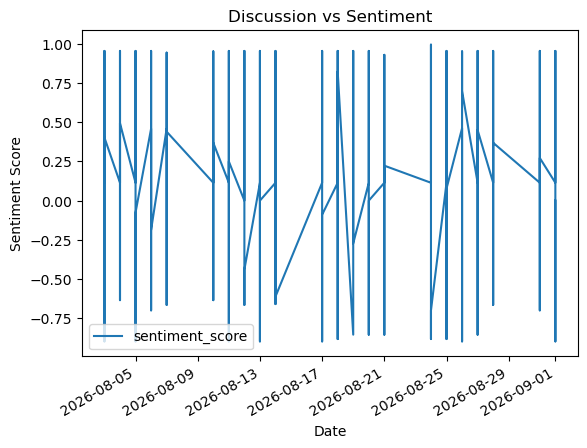

In [48]:
df.plot(x='date', y='sentiment_score')
plt.title("Discussion vs Sentiment")
plt.xlabel("Date")
plt.ylabel("Sentiment Score")
plt.show()

In [58]:
top1 = (
    df.sort_values(['date', 'sentiment_score'], ascending=[True, False])
      .groupby('date')
      .head(1)
      .reset_index(drop=True)
)

top5.head(10)

,ticker,sentiment,sentiment_score,no_of_comments,date
0,GOOG,Bullish,0.955,5,2026-08-03
1,CD,Bullish,0.862,20,2026-08-03
2,EPS,Bullish,0.788,3,2026-08-03
3,UI,Bullish,0.758,3,2026-08-03
4,NYC,Bullish,0.710,2,2026-08-03
5,GOOG,Bullish,0.955,4,2026-08-04
6,HYSA,Bullish,0.952,13,2026-08-04
7,EU,Bullish,0.944,11,2026-08-04
8,CD,Bullish,0.862,4,2026-08-04
9,MRVL,Bullish,0.823,3,2026-08-04


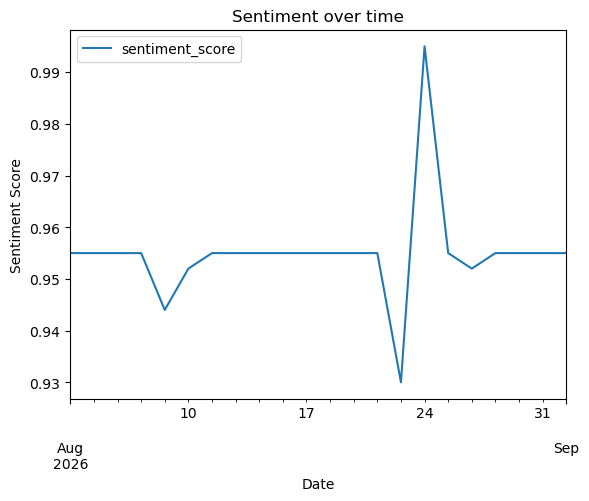

In [59]:
top1.plot( x='date', y='sentiment_score')
plt.title("Sentiment over time")
plt.xlabel("Date")
plt.ylabel("Sentiment Score")
plt.show()

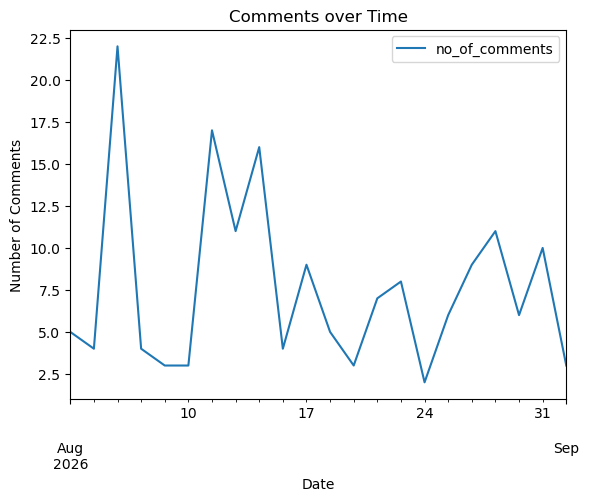

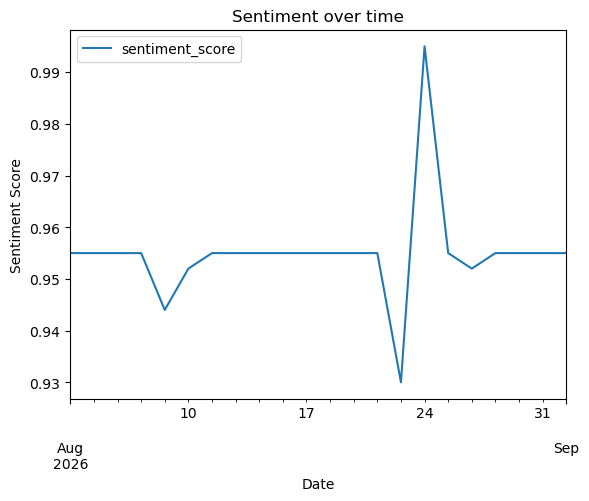

In [60]:
top1.plot( x='date', y='no_of_comments')
plt.title("Comments over Time")
plt.xlabel("Date")
plt.ylabel("Number of Comments")
plt.show()

top1.plot( x='date', y='sentiment_score')
plt.title("Sentiment over time")
plt.xlabel("Date")
plt.ylabel("Sentiment Score")
plt.show()

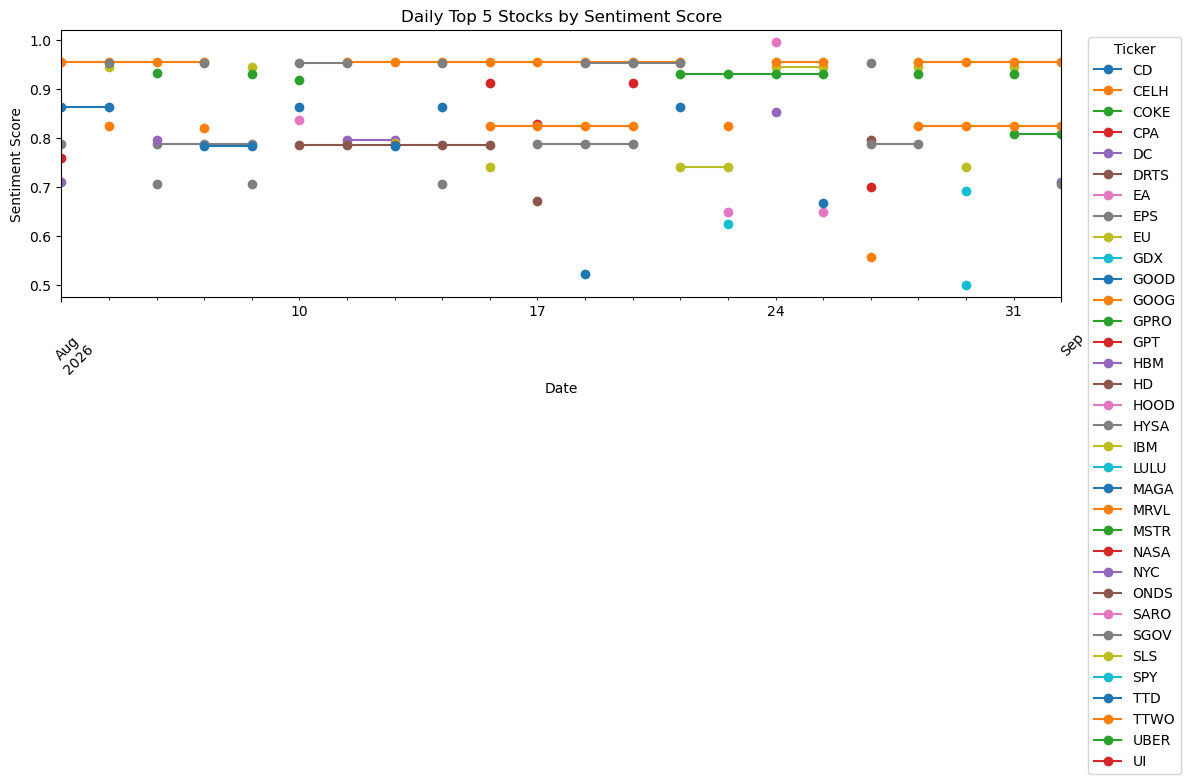

In [43]:
#claude made graph: test
pivot = top5.pivot(index='date', columns='ticker', values='sentiment_score')

pivot.plot(figsize=(12, 6), marker='o')
plt.title('Daily Top 5 Stocks by Sentiment Score')
plt.xlabel('Date')
plt.ylabel('Sentiment Score')
plt.legend(title='Ticker', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
top_tickers = (
    df.groupby('ticker')['sentiment_score']
      .mean()
      .nlargest(5)
      .index
)
df

,ticker,sentiment,sentiment_score,no_of_comments,date
0,AI,Bullish,0.114,130,2026-08-03
1,SPY,Bullish,0.500,65,2026-08-03
2,MU,Bullish,0.226,63,2026-08-03
3,PLTR,Bearish,-0.043,55,2026-08-03
4,RDDT,Bullish,0.014,22,2026-08-03
...,...,...,...,...,...
1095,NYC,Bullish,0.710,2,2026-09-01
1096,VTI,Bearish,-0.398,2,2026-09-01
1097,SOXX,Bearish,0.000,2,2026-09-01
1098,AGI,Bullish,0.369,2,2026-09-01


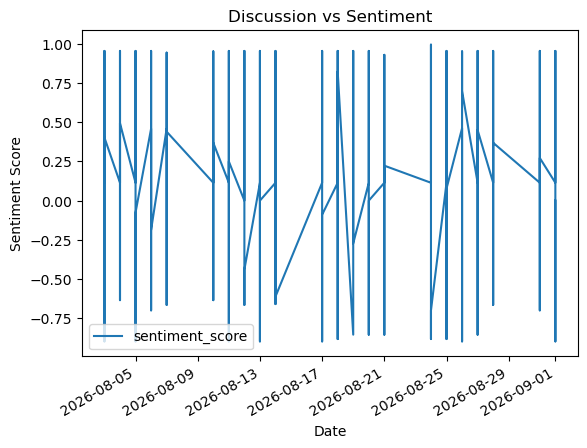

In [45]:
df.plot( x='date', y='sentiment_score')
plt.title("Discussion vs Sentiment")
plt.xlabel("Date")
plt.ylabel("Sentiment Score")
plt.show()